# STLRocket pipeline, end to end

One dataset, one seed, every step of the method. The architecture exists to be **interpretable**: the classifier only sees robustness values of STL formulae, so every explanation is itself an STL formula, a statement about the series in its own units and in seconds that anyone can check by eye. Steps 4b and 7b show this.

1. data and standardization
2. bank of STL formulae, centred with class-balanced weights
3. LASSO classifier: **balanced accuracy on train and test**
4. the instance explanation of one prediction, step by step
4b. **reading an instance explanation**: in words, each condition checked on the series, the evidence of the model it comes from, and one explanation per class
5. **explanations in the units of the original series**: the thresholds read directly on the raw data
6. instance explanations of the whole test set: **precision, recall and size**
7. global explanations: **precision, recall, F1 and size of each class, and how they separate the classes**
7b. **reading the global explanations**: each class as a short list of rules in words, and how much of the class each rule covers

All metrics are with respect to the predictions of the classifier and computed on the explanations as built (before simplification), as in the paper. Sizes are the numbers of nodes of the simplified STL formulae, which is what a reader sees.

In [34]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "local_experiments" else Path.cwd()
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "scripts"))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from aeon.datasets import load_classification
from sklearn.metrics import balanced_accuracy_score
from sklearn.utils.class_weight import compute_sample_weight

from plot_comparison import INK, INK_2, GRID, style_axis      # paper style (also sets its rcParams)
from case_study import CLASS_COLORS
from stlrocket.config import ExperimentConfig
from stlrocket.data import load_dataset, _fill_missing
from stlrocket.features import build_formula_bank, eval_robustness
from stlrocket.classifier import train_classifier
from stlrocket.formula_sampler import F0
from stlrocket import instance_rules as ir
from stlrocket.pretty import DATASET_INFO, to_original_units, atom_spans, atom_threshold, nnf

DATASET, SEED = "Epilepsy", 0     # also works with "BasicMotions" (DATASET_INFO has their variable names)
pd.set_option("display.max_colwidth", 200)
OTHER = "#b3b3b3"                 # series of the other classes
plt.rcParams.update({"font.family": "sans-serif", "mathtext.fontset": "dejavusans"})   # paper font lacks <, >, _ in text

## 1. Data

`load_dataset` fills missing values and standardizes every variable with its mean $m_v$ and std $s_v$ over all train series and time steps; with `return_stats=True` it also returns them. The original series are loaded separately, filled in the same way.

In [35]:
X_tr, y_tr, X_te, y_te, mean, std = load_dataset(DATASET, return_stats=True)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    X_raw = {s: _fill_missing(load_classification(DATASET, split=s.upper())[0].astype(np.float32)) for s in ("train", "test")}
info = DATASET_INFO[DATASET]
T = X_tr.shape[2]
t_sec = np.arange(T) / info.hz
print(f"train {X_tr.shape}, test {X_te.shape}  (series, variables, time steps), sampled at {info.hz} Hz")
print("classes:", {str(c): int(n) for c, n in zip(*np.unique(y_tr, return_counts=True))})
pd.DataFrame({"mean m_v": mean, "std s_v": std}, index=info.var_names).round(3)

train (137, 3, 206), test (138, 3, 206)  (series, variables, time steps), sampled at 16.0 Hz
classes: {'epilepsy': 34, 'running': 36, 'sawing': 30, 'walking': 37}


,mean m_v,std s_v
acc_x,0.070,0.968
acc_y,-0.290,1.020
acc_z,-0.102,0.512


## 2. Bank of STL formulae

$M = 10^4$ formulae of depth at most 2, without until. Each formula is shifted with the robustness shift property so that its robustness has zero **class-balanced** mean on train, and its feature is that robustness divided by its class-balanced std.

In [36]:
cfg = ExperimentConfig(
    dataset=DATASET, n_formulas=10_000, depth_max=2, until_weight=0.0, cv=3, cut_point=1.0,
    fit_intercept=False, n_run=1, base_seed=SEED, output_dir=".", device="cpu", explain=False, pool_size=0,
    precision_threshold=0.0, simplify_agreement=0.0, simplify_min_gain=0.0, simplify_decimals=0)
formulas, F_tr, F_te, sigma = build_formula_bank(X_tr, X_te, y_tr, cfg, SEED)

w = compute_sample_weight("balanced", y_tr)
live = np.any(F_tr != 0, axis=0)
sd = np.sqrt(np.average(F_tr[:, live] ** 2, axis=0, weights=w))
print(f"{F_tr.shape[1]} features, {(~live).sum()} constant on train")
print(f"class-balanced mean on train: max |.| = {np.abs(np.average(F_tr[:, live], axis=0, weights=w)).max():.1e}")
print(f"class-balanced std on train: min {sd.min():.4f}, max {sd.max():.4f}")
print()
for j in range(3):
    print(f"phi_{j}:", formulas[j])

10000 features, 0 constant on train
class-balanced mean on train: max |.| = 7.5e-07
class-balanced std on train: min 1.0000, max 1.0000

phi_0: ( always[77,142] ( x_1 <= -6.8195 ) ) or ( eventually[64,90] ( x_2 <= -1.022 ) )
phi_1: always ( eventually[163,168] ( x_0 >= 0.1184 ) )
phi_2: ( eventually[102,148] ( x_2 <= -1.1631 ) ) or ( eventually[186,inf] ( x_1 <= -3.1082 ) )


## 3. Classifier

Multinomial logistic regression without intercept, LASSO penalty, $\lambda$ chosen by 3-fold cross-validation on balanced accuracy with the one-standard-error rule. Only the formulae with a non-zero weight can appear in an explanation.

In [37]:
model = train_classifier(F_tr, y_tr, cfg, seed=SEED)
W = ir.model_logits_matrix(model)
classes = model.classes_
K = len(classes)
index = {c: i for i, c in enumerate(classes)}
true = {"train": np.array([index[c] for c in y_tr]), "test": np.array([index[c] for c in y_te])}
F = {"train": F_tr, "test": F_te}
X = {"train": X_tr, "test": X_te}
pred = {s: ir.predict_indices(F[s], W) for s in F}
S = np.flatnonzero(np.any(W != 0, axis=0))
print(f"{len(S)} of {len(formulas)} formulae selected\n")
pd.DataFrame({"balanced accuracy": [balanced_accuracy_score(true[s], pred[s]) for s in ("train", "test")],
              "series": [len(true[s]) for s in ("train", "test")]}, index=["train", "test"]).round(3)

40 of 10000 formulae selected



,balanced accuracy,series
train,1.000,137
test,0.958,138


## 4. Instance explanation of one prediction, step by step

**Candidates.** For the predicted class $k$, $A_{l,j} = (w_{k,j} - w_{l,j})\,x_j$ is the contribution of formula $j$ to the margin of $k$ over class $l$. The Gradient × Input score $s_j = \sum_{l \ne k} P(l\mid x)\,A_{l,j}$ ranks the formulae; the candidates are those with $s_j > 0$.

In [38]:
i = 0                                  # test series to explain
x = F_te[i]
k, s, J = ir.candidate_scores(x, W, "gxi")
print(f"test series {i}: true class {y_te[i]}, predicted {classes[k]}; {len(J)} candidates")
pd.DataFrame({"formula": [f"{formulas[j]}" for j in J[:8]], "s_j": s[J[:8]].round(3), "x_j(tau)": x[J[:8]].round(2)})

test series 0: true class epilepsy, predicted epilepsy; 30 candidates


,formula,s_j,x_j(tau)
0,"always[96,inf] ( ( x_0 >= -1.7125 ) and ( x_0 <= 1.796 ) )",1.347,1.13
1,"( always[50,163] ( x_0 >= -2.2407 ) ) and ( always[187,inf] ( x_0 <= 1.0701 ) )",0.817,2.17
2,"( always[5,182] ( x_1 >= -0.2946 ) ) or ( always[142,203] ( x_1 <= 0.6576 ) )",0.458,-1.99
3,"always[16,204] ( ( x_2 >= -0.6204 ) or ( x_1 <= 0.6639 ) )",0.415,-2.09
4,"( always[0,inf] ( x_1 <= 0.8095 ) ) or ( always[16,202] ( x_1 >= -0.4146 ) )",0.388,-1.71
5,"( eventually ( x_2 <= -0.6822 ) ) and ( always[130,186] ( x_0 <= 1.2743 ) )",0.355,2.11
6,"( always ( x_1 <= 1.0233 ) ) or ( eventually[98,157] ( x_1 >= 3.0346 ) )",0.247,-1.63
7,"( eventually[38,62] ( x_0 >= 1.5209 ) ) or ( always ( x_1 <= 0.6891 ) )",0.220,-1.79


**Construction (ordered scan).** The candidates are visited by decreasing score. For each, the threshold with the largest precision lower bound (one-sided Wilson bound at 0.95 on the train series) is chosen, and the literal is added only if it raises the bound of the rule; at most 3 literals. By the shift property the rule is an STL formula, then simplified without changing which train series satisfy it.

In [39]:
rcfg = ir.RuleConfig()                 # n_max=3, confidence=0.95, ordered_scan, gxi, min_new_share=0.05
r = ir.explain_instance(x, W, F_tr, pred["train"], rcfg)
for j, e, c in r["literals"]:
    print(f"  phi_{j}: {'+' if e > 0 else '-'}x_{j} > {c:.3f}   (score rank {list(J).index(j) + 1})")
print(f"train: support {r['support']}, TP {r['tp']}, precision {r['precision']:.3f}, plb {r['lcb']:.3f}\n")
phi_built = ir.to_stl(r["literals"], formulas, sigma)
phi = ir.rule_formula(r["literals"], formulas, sigma, X_tr)
print("built      :", phi_built, f"  ({F0.formula_size(phi_built)} nodes)")
print("simplified :", phi, f"  ({F0.formula_size(phi)} nodes)")

  phi_4654: +x_4654 > 1.039   (score rank 1)
train: support 19, TP 19, precision 1.000, plb 0.875

built      : always[96,inf] ( ( x_0 >= -0.9341 ) and ( x_0 <= 1.0176 ) )   (4 nodes)
simplified : always[96,inf] ( ( x_0 >= -0.9341 ) and ( x_0 <= 1.0176 ) )   (4 nodes)


## 5. Explanations in the units of the original series

The method works on standardized series, but nothing is lost: an atom $x_v > c$ on the standardized series is
$$\tilde x_v > m_v + c\,s_v$$
on the original one. `to_original_units` rewrites every atom this way and gives an STL formula that is evaluated **directly on the raw series**, satisfied by exactly the same series. (Robustness values change, since each atom's is multiplied by $s_v$; only the sign is meant to be read.)

In [40]:
phi_orig = to_original_units(nnf(phi), mean, std)   # nnf: negations pushed into the atoms, same robustness
print("standardized   :", nnf(phi))
print("original units :", phi_orig)


standardized   : always[96,inf] ( ( x_0 >= -0.9341 ) and ( x_0 <= 1.0176 ) )
original units : always[96,inf] ( ( x_0 >= -0.8348 ) and ( x_0 <= 1.0552 ) )


The atoms of the explanation drawn on the **raw** test series: the y axis is in the units of the original data, and the dashed line is the threshold the explanation states, over the time span it is read on (shaded). Coloured band: the test series predicted as the same class (5-95% at each time step, with the median); grey: the other classes; black: the explained series.

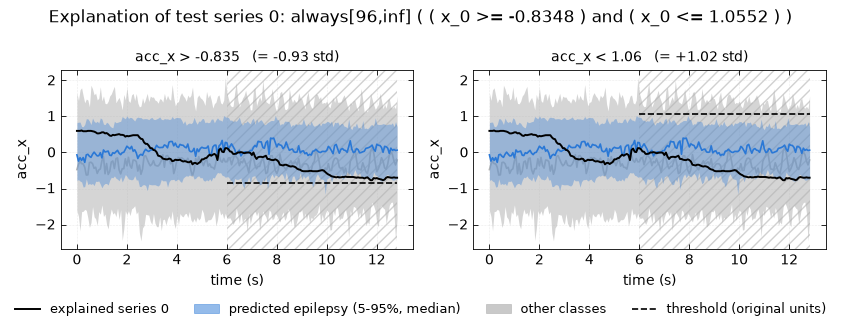

In [41]:
def draw_atoms(phi, k, ax_row, highlight=None):
    for ax, (a, t0, t1, _) in zip(ax_row, atom_spans(phi)):
        v = a.var_index
        t1 = T - 1 if t1 is None else min(t1, T - 1)
        own = pred["test"] == k
        # each group as its 5-95% band over the series at every time step, and its median
        for series, color, alpha, z in ((X_raw["test"][~own, v], OTHER, 0.55, 1),
                                        (X_raw["test"][own, v], CLASS_COLORS[k], 0.35, 2)):
            lo, med, hi = np.percentile(series, [5, 50, 95], axis=0)
            ax.fill_between(t_sec, lo, hi, color=color, alpha=alpha, lw=0, zorder=z)
            ax.plot(t_sec, med, color=color, lw=1.2, zorder=z + 0.5)
        if highlight is not None:
            ax.plot(t_sec, X_raw["test"][highlight, v], color=INK, lw=1.4, zorder=4)
        thr = atom_threshold(a, mean, std)
        ax.axvspan(t0 / info.hz, t1 / info.hz, facecolor="none", edgecolor=INK_2, hatch="///", lw=0, alpha=0.25, zorder=0)
        ax.hlines(thr, t0 / info.hz, t1 / info.hz, color=INK, ls="--", lw=1.2, zorder=5)
        ax.set_title(f"{info.var_names[v]} {'<' if a.lte else '>'} {thr:.3g}   "
                     f"(= {a.threshold:+.2f} std)", color=INK)
        ax.set_ylabel(info.var_names[v]); ax.set_xlabel("time (s)")
        style_axis(ax)

spans = atom_spans(phi)
fig, axes = plt.subplots(1, len(spans), figsize=(4.2 * len(spans), 3), squeeze=False)
draw_atoms(phi, k, axes[0], highlight=i)
from matplotlib.patches import Patch
handles = [plt.Line2D([], [], color=INK, lw=1.4, label=f"explained series {i}"),
           Patch(color=CLASS_COLORS[k], alpha=0.5, label=f"predicted {classes[k]} (5-95%, median)"),
           Patch(color=OTHER, alpha=0.7, label="other classes"),
           plt.Line2D([], [], color=INK, ls="--", label="threshold (original units)")]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.08))
fig.suptitle(f"Explanation of test series {i}: {phi_orig}", color=INK)
plt.tight_layout()

## 6. Global explanations as regions

In [47]:
train_rules = ir.explain_instances(F_tr, W, F_tr, pred["train"], rcfg, train=True)
G = ir.global_explanations(train_rules, F_tr, X_tr, pred["train"], formulas, sigma, rcfg, simplify=False)

G_simple = ir.global_explanations(train_rules, F_tr, X_tr, pred["train"], formulas, sigma, rcfg, simplify=True)
for kk, phis in sorted(G_simple.items()):
    print(f"G({classes[kk]}):  {len(phis)} disjuncts, "
        f"{sum(F0.formula_size(p) for p in phis) + len(phis) - 1} nodes")
    for p in phis:
        print("   ", to_original_units(nnf(p), mean, std))


G(epilepsy):  3 disjuncts, 34 nodes
    ( always[96,inf] ( ( x_0 >= -1.1446 ) and ( x_0 <= 1.365 ) ) ) and ( ( always[50,163] ( x_0 >= -1.9591 ) ) and ( always[187,inf] ( x_0 <= 0.965 ) ) )
    ( ( always[96,inf] ( ( x_0 >= -1.1796 ) and ( x_0 <= 1.4 ) ) ) and ( eventually[94,inf] ( x_0 >= -0.0022 ) ) ) and ( ( eventually[0,inf] ( x_1 >= 0.7322 ) ) and ( eventually[16,202] ( x_1 <= -0.91 ) ) )
    ( ( always[50,163] ( x_0 >= -1.432 ) ) and ( always[187,inf] ( x_0 <= 0.438 ) ) ) and ( eventually ( x_2 <= -0.5198 ) )
G(running):  2 disjuncts, 17 nodes
    ( eventually[35,146] ( ( x_1 <= -3.025 ) or ( x_1 >= 2.2712 ) ) ) and ( ( eventually[145,189] ( x_0 >= 1.711 ) ) or ( eventually[119,128] ( x_0 <= -1.37 ) ) )
    eventually[35,146] ( ( x_1 <= -3.44 ) or ( x_1 >= 2.6862 ) )
G(sawing):  2 disjuncts, 20 nodes
    ( ( always ( eventually[37,41] ( x_0 >= 0.255 ) ) ) and ( always[3,190] ( eventually[0,3] ( x_2 <= -0.19 ) ) ) ) and ( always[45,78] ( x_2 <= 0.3 ) )
    ( eventually[30,31] ( x_

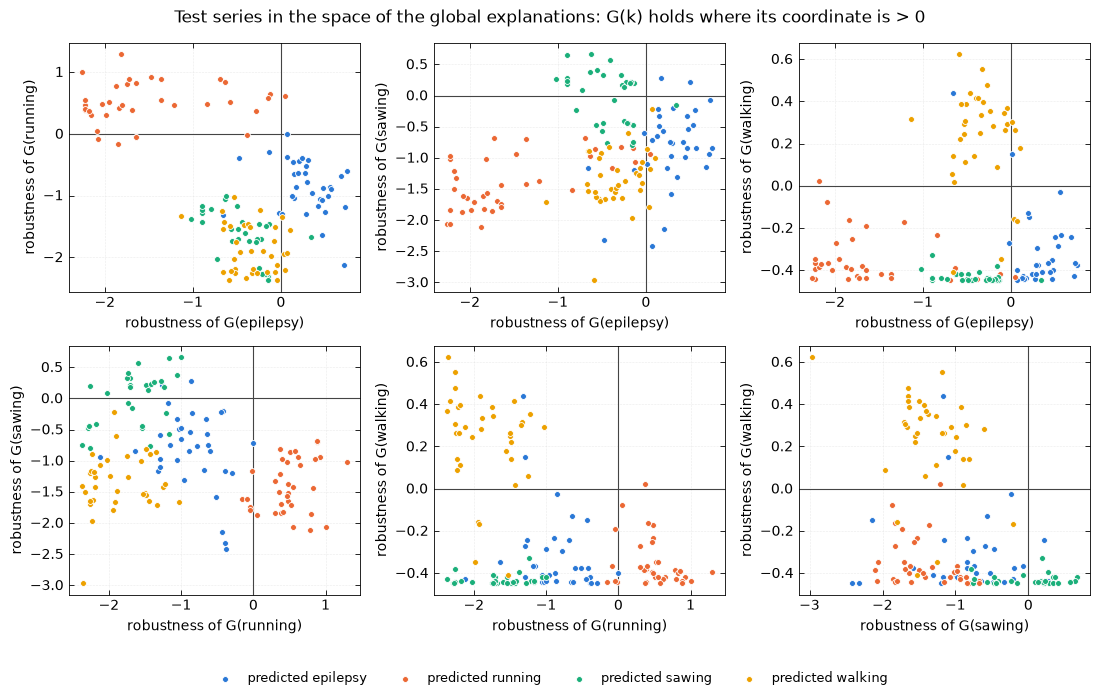

In [43]:

R = np.full((len(X_te), K), np.nan)            # robustness of G(k) on every test series
for kk, phis in G.items():
    R[:, kk] = np.max([eval_robustness(p, X_te) for p in phis], axis=0)

pairs = [(a, b) for a in range(K) for b in range(a + 1, K) if a in G and b in G]
n_cols = min(3, len(pairs))
fig, axes = plt.subplots(int(np.ceil(len(pairs) / n_cols)), n_cols, figsize=(3.7 * n_cols, 3.4 * np.ceil(len(pairs) / n_cols)),
                         squeeze=False)
for ax, (a, b) in zip(axes.ravel(), pairs):
    ax.axvline(0, color=INK_2, lw=0.8); ax.axhline(0, color=INK_2, lw=0.8)
    for kk in range(K):
        m = pred["test"] == kk
        ax.scatter(R[m, a], R[m, b], s=18, color=CLASS_COLORS[kk], edgecolor="white", linewidth=0.6,
                   label=f"predicted {classes[kk]}", zorder=3)
    ax.set_xlabel(f"robustness of G({classes[a]})"); ax.set_ylabel(f"robustness of G({classes[b]})")
    style_axis(ax)
for ax in axes.ravel()[len(pairs):]:
    ax.set_visible(False)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", ncol=K, frameon=False, bbox_to_anchor=(0.5, -0.03))
fig.suptitle("Test series in the space of the global explanations: G(k) holds where its coordinate is > 0", color=INK)
plt.tight_layout(rect=(0, 0.04, 1, 1))

**The same series in a t-SNE of the selected features.** For comparison, a t-SNE embedding of the test series in the space of the selected features. It shows how the classifier's features group the series, but it can only mark which series an explanation holds on: a half-space has no shape in a nonlinear embedding, so the regions themselves cannot be drawn. Circled: the series on which the global explanation of their predicted class does not hold.

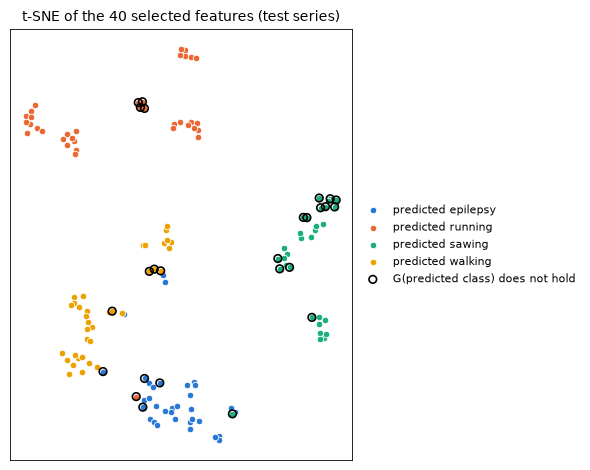

In [44]:
from sklearn.manifold import TSNE

S = np.flatnonzero(np.any(W != 0, axis=0))
E = TSNE(n_components=2, perplexity=min(5, (len(X_te) - 1) // 3), random_state=SEED).fit_transform(F_te[:, S])
missed = ~(R[np.arange(len(X_te)), pred["test"]] > 0)      # G(predicted class) does not hold (or does not exist)
fig, ax = plt.subplots(figsize=(6, 4.8))
for kk in range(K):
    m = pred["test"] == kk
    ax.scatter(E[m, 0], E[m, 1], s=22, color=CLASS_COLORS[kk], edgecolor="white", linewidth=0.6,
               label=f"predicted {classes[kk]}", zorder=3)
ax.scatter(E[missed, 0], E[missed, 1], s=30, facecolor="none", edgecolor=INK, lw=1.2, zorder=4,
           label="G(predicted class) does not hold")
ax.set_xticks([]); ax.set_yticks([])
ax.set_title(f"t-SNE of the {len(S)} selected features (test series)", color=INK)
ax.legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()